# Schelling's segregation model in 40 lines

Mild individual preferences, strong collective segregation.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
rng = np.random.default_rng(11)

N, F, EMPTY = 30, 0.30, 0.10
cells = np.array(["R"] * int(N * N * (1 - EMPTY) / 2) + ["B"] * int(N * N * (1 - EMPTY) / 2))
cells = np.concatenate([cells, np.array(["."] * (N * N - len(cells)))])
rng.shuffle(cells)
grid = cells.reshape(N, N)

def share_like_me(g, r, c):
    me, same, occ = g[r, c], 0, 0
    for dr in (-1, 0, 1):
        for dc in (-1, 0, 1):
            if (dr or dc) and 0 <= r + dr < N and 0 <= c + dc < N and g[r + dr, c + dc] != ".":
                occ += 1
                same += g[r + dr, c + dc] == me
    return same / occ if occ else 1.0

def unsatisfied(g):
    return [(r, c) for r in range(N) for c in range(N) if g[r, c] != "." and share_like_me(g, r, c) < F]

def mean_share(g):
    return np.mean([share_like_me(g, r, c) for r in range(N) for c in range(N) if g[r, c] != "."])

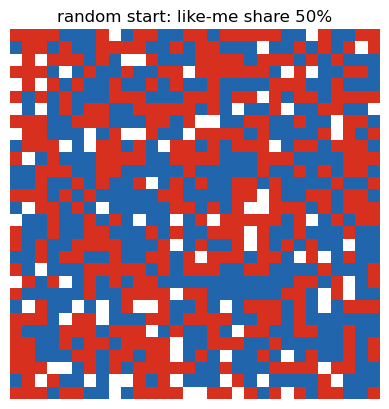

In [2]:
def show(g, title):
    img = np.vectorize({"R": 0, "B": 1, ".": 2}.get)(g)
    plt.imshow(img, cmap=plt.matplotlib.colors.ListedColormap(["#d7301f", "#2166ac", "white"]))
    plt.title(title); plt.axis("off"); plt.show()

show(grid, f"random start: like-me share {mean_share(grid):.0%}")

stable after 5 rounds


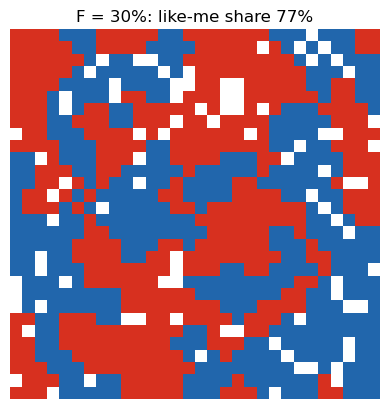

In [3]:
for round_ in range(50):
    movers = unsatisfied(grid)
    if not movers:
        break
    rng.shuffle(movers)
    for r, c in movers:
        empties = list(zip(*np.where(grid == ".")))
        rng.shuffle(empties)
        for er, ec in empties:                       # closest satisfying cell, simplified to: any satisfying cell
            grid[er, ec] = grid[r, c]
            if share_like_me(grid, er, ec) >= F:
                grid[r, c] = "."
                break
            grid[er, ec] = "."
print(f"stable after {round_} rounds")
show(grid, f"F = {F:.0%}: like-me share {mean_share(grid):.0%}")

Everyone asked for 30%; the typical neighborhood ends up far above it. Change
`F` and run it again: 0.5 is stark, and 0.25 still segregates.

## Reading the end state backwards is a mistake

The rule of the agents is visible in the code. Given only the final grid, would
you have guessed a 30% threshold?

**What we used:** agent-based modeling, generative sufficiency and Schelling's
model (session 13, sections 13 and 14).